# Machine Learning Project
## Comparing K-Nearest Neighbors (KNN) and Decision Tree (ID3)
### Dataset: Heart Disease — UCI Machine Learning Repository
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

---
## Step 1: Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

print('Libraries loaded successfully!')

Libraries loaded successfully!


---
## Step 2: Load Dataset

**Dataset:** Heart Disease (Cleveland) from UCI Repository  
**Samples:** 303 rows  
**Features:** 13 features (age, sex, chest pain type, blood pressure, etc.)  
**Classes:** Binary — 0 = No Disease, 1 = Disease Present  
**Missing values:** Yes (in 'ca' and 'thal' columns — marked as '?')

In [3]:
# Column names based on UCI Heart Disease dataset
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs',
    'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

# Load the dataset — put processed.cleveland.data in the same folder as this notebook
df = pd.read_csv('processed.cleveland.data', names=columns, na_values='?')

print('Dataset shape:', df.shape)
df.head(10)

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
5,56.0,1.0,2.0,120.0,236.0,0.0,0.0,178.0,0.0,0.8,1.0,0.0,3.0,0
6,62.0,0.0,4.0,140.0,268.0,0.0,2.0,160.0,0.0,3.6,3.0,2.0,3.0,3
7,57.0,0.0,4.0,120.0,354.0,0.0,0.0,163.0,1.0,0.6,1.0,0.0,3.0,0
8,63.0,1.0,4.0,130.0,254.0,0.0,2.0,147.0,0.0,1.4,2.0,1.0,7.0,2
9,53.0,1.0,4.0,140.0,203.0,1.0,2.0,155.0,1.0,3.1,3.0,0.0,7.0,1


---
## Step 3: Data Exploration

In [4]:
# General info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [5]:
# Check missing values
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [6]:
# Statistical summary
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [7]:
# Class distribution before encoding
print('Target value counts (raw):')
print(df['target'].value_counts())

Target value counts (raw):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


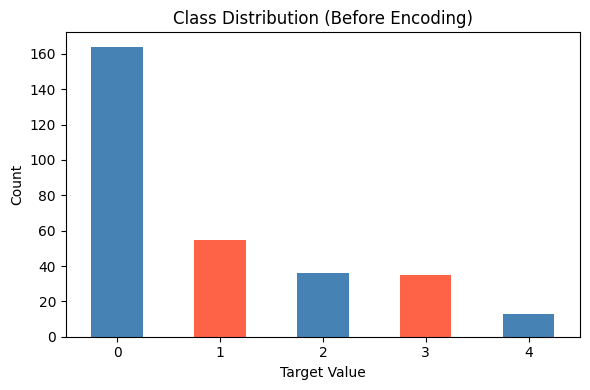

In [8]:
# Visualize class distribution
plt.figure(figsize=(6, 4))
df['target'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'])
plt.title('Class Distribution (Before Encoding)')
plt.xlabel('Target Value')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---
## Step 4: Data Preprocessing

In [9]:
# Handle missing values — impute with mode (most frequent value)
df['ca'] = df['ca'].fillna(df['ca'].mode()[0])
df['thal'] = df['thal'].fillna(df['thal'].mode()[0])

print('Missing values after imputation:')
print(df.isnull().sum())

Missing values after imputation:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


In [10]:
# Encode target: 0 = No Disease, 1 = Disease (any level > 0)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

print('Class distribution after binary encoding:')
print(df['target'].value_counts())
print('\n0 = No Disease | 1 = Disease Present')

Class distribution after binary encoding:
target
0    164
1    139
Name: count, dtype: int64

0 = No Disease | 1 = Disease Present


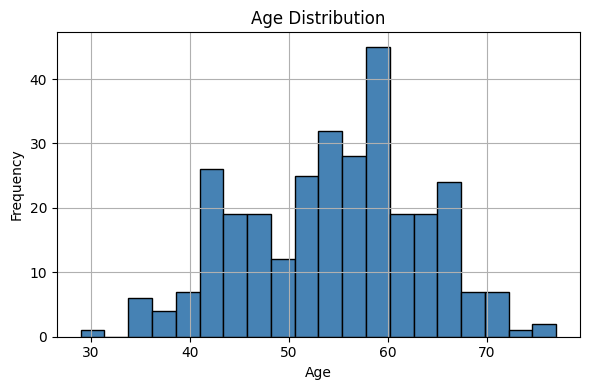

In [11]:
# Visualize age distribution
df.hist(column='age', bins=20, figsize=(6, 4), color='steelblue', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

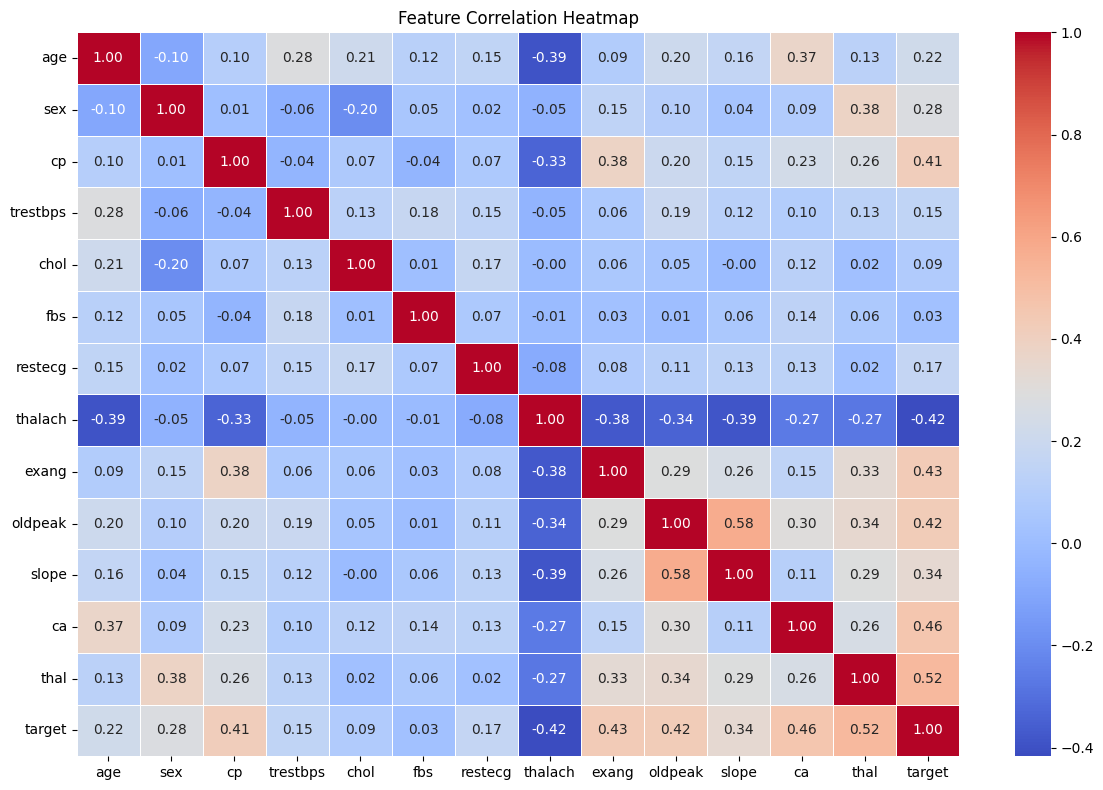

In [12]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [13]:
# Separate Features (X) and Labels (y)
X = df.drop('target', axis=1)
y = df['target']

feature_names = X.columns.tolist()
class_names = ['No Disease', 'Disease']

print('Features shape:', X.shape)
print('Labels shape:', y.shape)
print('Features:', feature_names)

Features shape: (303, 13)
Labels shape: (303,)
Features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


---
## Step 5: Train / Test Split (80% / 20%)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True, stratify=y
)

print('Train set:', X_train.shape, y_train.shape)
print('Test set: ', X_test.shape,  y_test.shape)

Train set: (242, 13) (242,)
Test set:  (61, 13) (61,)


---
## Step 6: Normalization / Scaling
**(Required for KNN — distance-based algorithm)**

In [15]:
# StandardScaler: zero mean, unit variance
scaler = preprocessing.StandardScaler()
X_train_norm = scaler.fit_transform(X_train.astype(float))
X_test_norm  = scaler.transform(X_test.astype(float))

print('Normalization applied (StandardScaler)')
print('First 3 normalized training rows:')
print(X_train_norm[:3])

Normalization applied (StandardScaler)
First 3 normalized training rows:
[[-0.72948484  0.68313005  0.8701687  -0.39569185  0.4581394  -0.41119597
   1.0229958   0.70837124 -0.69617712 -0.44544493  0.67505958 -0.68971531
   1.17997269]
 [ 0.05016647  0.68313005 -1.18427838 -0.05451337  0.23059762 -0.41119597
  -0.98157896  0.22249537 -0.69617712 -0.89162735 -0.9585846  -0.68971531
  -0.87806977]
 [-0.06121229 -1.46385011 -1.18427838  0.0592128   0.72360482  2.43193045
   1.0229958   0.3991775   1.43641607 -0.89162735 -0.9585846   0.44573438
  -0.87806977]]


---
## Step 7: Model 1 — K-Nearest Neighbors (KNN)

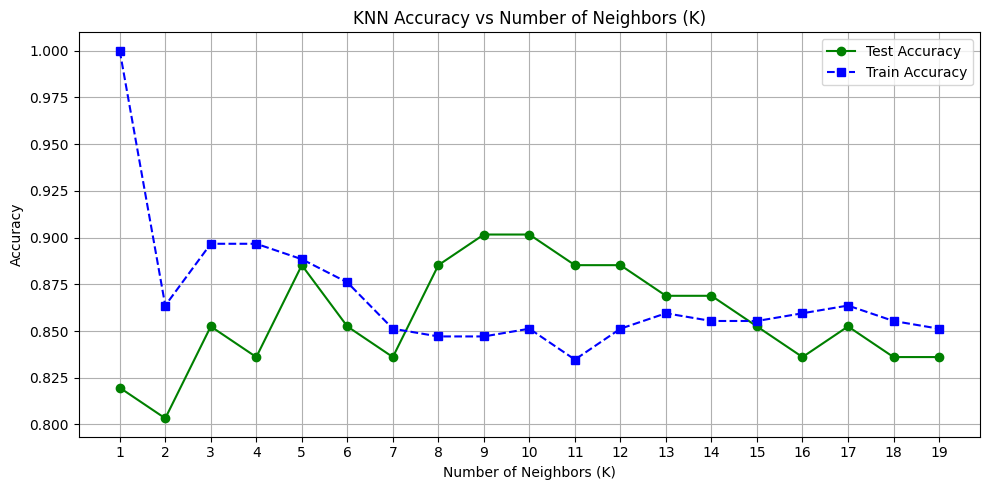

Best K = 9  |  Test Accuracy = 0.9016


In [16]:
# Test multiple K values to find the best K
Ks = 20
mean_acc = np.zeros(Ks - 1)
train_acc = np.zeros(Ks - 1)

for n in range(1, Ks):
    knn = KNeighborsClassifier(n_neighbors=n).fit(X_train_norm, y_train)
    yhat = knn.predict(X_test_norm)
    mean_acc[n-1]  = accuracy_score(y_test, yhat)
    train_acc[n-1] = accuracy_score(y_train, knn.predict(X_train_norm))

# Plot accuracy vs K
plt.figure(figsize=(10, 5))
plt.plot(range(1, Ks), mean_acc,  'g-o', label='Test Accuracy')
plt.plot(range(1, Ks), train_acc, 'b--s', label='Train Accuracy')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs Number of Neighbors (K)')
plt.legend()
plt.xticks(range(1, Ks))
plt.grid(True)
plt.tight_layout()
plt.show()

best_k = mean_acc.argmax() + 1
print(f'Best K = {best_k}  |  Test Accuracy = {mean_acc.max():.4f}')

In [17]:
# Train final KNN model with best K
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_train_norm, y_train)

# Predict
y_pred_knn = knn_model.predict(X_test_norm)

print(f'KNN Model trained with K = {best_k}')
print('Predictions (first 10):', y_pred_knn[:10])
print('Actual      (first 10):', y_test.values[:10])

KNN Model trained with K = 9
Predictions (first 10): [0 1 0 0 1 0 0 0 1 0]
Actual      (first 10): [0 0 0 0 0 0 0 0 1 0]


### KNN — Evaluation

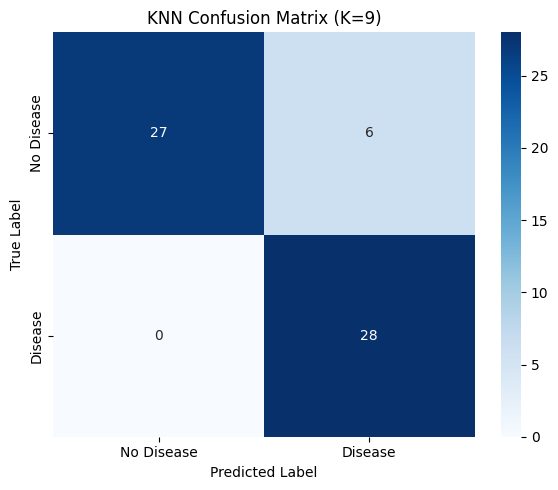

In [18]:
# Confusion Matrix — KNN
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'KNN Confusion Matrix (K={best_k})')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [19]:
# KNN — Classification Report
print('=== KNN Classification Report ===')
print(classification_report(y_test, y_pred_knn, target_names=class_names))

knn_acc = accuracy_score(y_test, y_pred_knn)
knn_prec = precision_score(y_test, y_pred_knn, average='weighted')
knn_rec  = recall_score(y_test, y_pred_knn, average='weighted')
knn_f1   = f1_score(y_test, y_pred_knn, average='weighted')

print(f'Accuracy  : {knn_acc:.4f}')
print(f'Precision : {knn_prec:.4f}')
print(f'Recall    : {knn_rec:.4f}')
print(f'F1-Score  : {knn_f1:.4f}')

=== KNN Classification Report ===
              precision    recall  f1-score   support

  No Disease       1.00      0.82      0.90        33
     Disease       0.82      1.00      0.90        28

    accuracy                           0.90        61
   macro avg       0.91      0.91      0.90        61
weighted avg       0.92      0.90      0.90        61

Accuracy  : 0.9016
Precision : 0.9190
Recall    : 0.9016
F1-Score  : 0.9015


### KNN — Cross Validation (5-Fold)
للتحقق من أن النموذج لا يعتمد على تقسيم معين للبيانات

Cross-Validation Accuracy per fold:
  Fold 1: 0.8852
  Fold 2: 0.8197
  Fold 3: 0.8361
  Fold 4: 0.8000
  Fold 5: 0.8167

Mean CV Accuracy : 0.8315
Std CV Accuracy  : 0.0292


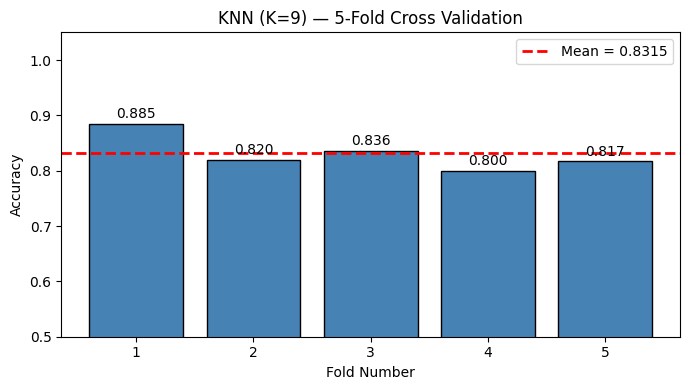

In [ ]:
# 5-Fold Cross Validation on best KNN model
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(knn_model, 
                            preprocessing.StandardScaler().fit_transform(X.astype(float)), 
                            y, cv=cv, scoring='accuracy')

print('Cross-Validation Accuracy per fold:')
for i, score in enumerate(cv_scores):
    print(f'  Fold {i+1}: {score:.4f}')
print(f'\nMean CV Accuracy : {cv_scores.mean():.4f}')
print(f'Std CV Accuracy  : {cv_scores.std():.4f}')

# Plot
plt.figure(figsize=(7, 4))
bars = plt.bar(range(1, 6), cv_scores, color='steelblue', edgecolor='black')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', linewidth=2,
            label=f'Mean = {cv_scores.mean():.4f}')
for bar, score in zip(bars, cv_scores):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{score:.3f}', ha='center', va='bottom', fontsize=10)
plt.xlabel('Fold Number')
plt.ylabel('Accuracy')
plt.title(f'KNN (K={best_k}) — 5-Fold Cross Validation')
plt.ylim(0.5, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

### KNN — Distance Metric Comparison
مقارنة بين Euclidean و Manhattan لاختيار الأفضل

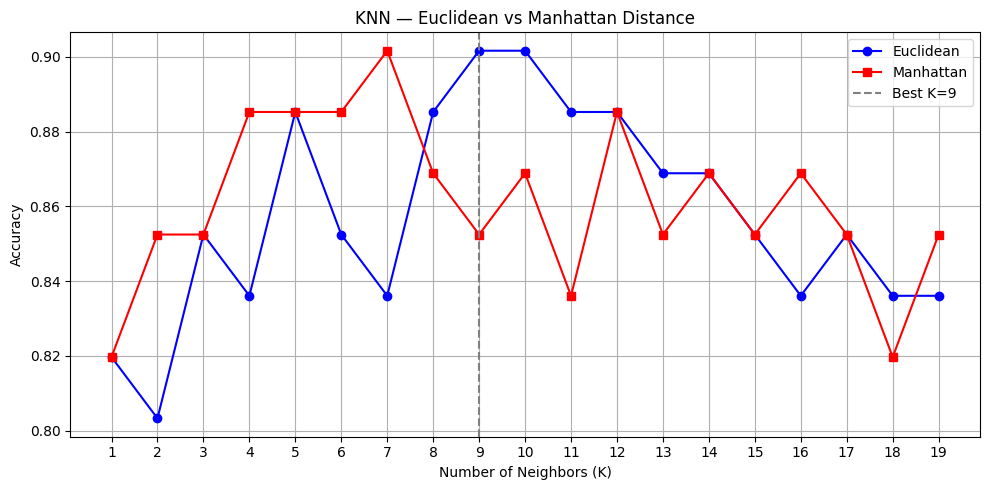

Best Accuracy (Euclidean): 0.9016
Best Accuracy (Manhattan): 0.9016
Winner: Euclidean with accuracy 0.9016


In [21]:
# Compare Euclidean vs Manhattan distance
metrics_compare = ['euclidean', 'manhattan']
metric_results = {}

for metric in metrics_compare:
    acc_list = []
    for n in range(1, 20):
        knn_m = KNeighborsClassifier(n_neighbors=n, metric=metric)
        knn_m.fit(X_train_norm, y_train)
        acc_list.append(accuracy_score(y_test, knn_m.predict(X_test_norm)))
    metric_results[metric] = acc_list

# Plot
plt.figure(figsize=(10, 5))
plt.plot(range(1, 20), metric_results['euclidean'], 'b-o', label='Euclidean')
plt.plot(range(1, 20), metric_results['manhattan'], 'r-s', label='Manhattan')
plt.axvline(x=best_k, color='gray', linestyle='--', label=f'Best K={best_k}')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Accuracy')
plt.title('KNN — Euclidean vs Manhattan Distance')
plt.legend()
plt.grid(True)
plt.xticks(range(1, 20))
plt.tight_layout()
plt.show()

best_euc = max(metric_results['euclidean'])
best_man = max(metric_results['manhattan'])
print(f'Best Accuracy (Euclidean): {best_euc:.4f}')
print(f'Best Accuracy (Manhattan): {best_man:.4f}')
print(f'Winner: {"Euclidean" if best_euc >= best_man else "Manhattan"}'
      f' with accuracy {max(best_euc, best_man):.4f}')

### KNN — Per-Class Metrics Visualization

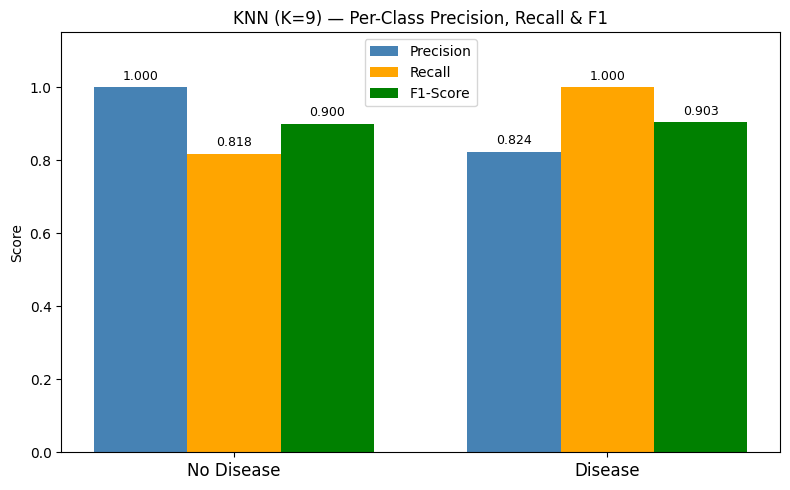


Class: No Disease  → Precision: 1.0000 | Recall: 0.8182 | F1: 0.9000 | Support: 33
Class: Disease     → Precision: 0.8235 | Recall: 1.0000 | F1: 0.9032 | Support: 28


In [22]:
# Per-class Precision, Recall, F1 bar chart
from sklearn.metrics import precision_recall_fscore_support

precision_per, recall_per, f1_per, support_per = precision_recall_fscore_support(
    y_test, y_pred_knn, labels=[0, 1]
)

x_labels = class_names
x = np.arange(len(x_labels))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width, precision_per, width, label='Precision', color='steelblue')
ax.bar(x,         recall_per,    width, label='Recall',    color='orange')
ax.bar(x + width, f1_per,        width, label='F1-Score',  color='green')

ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=12)
ax.set_ylim(0, 1.15)
ax.set_ylabel('Score')
ax.set_title(f'KNN (K={best_k}) — Per-Class Precision, Recall & F1')
ax.legend()

for rect in ax.patches:
    ax.annotate(f'{rect.get_height():.3f}',
                xy=(rect.get_x() + rect.get_width()/2, rect.get_height()),
                xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print(f'\nClass: No Disease  → Precision: {precision_per[0]:.4f} | Recall: {recall_per[0]:.4f} | F1: {f1_per[0]:.4f} | Support: {support_per[0]}')
print(f'Class: Disease     → Precision: {precision_per[1]:.4f} | Recall: {recall_per[1]:.4f} | F1: {f1_per[1]:.4f} | Support: {support_per[1]}')

---
## Step 8: Model 2 — Decision Tree (ID3 — Entropy Criterion)

## Train Decision Tree Model

### Subtask:
Initialize and train a Decision Tree Classifier using the training data. The model should use 'entropy' as the criterion for splitting, adhering to the ID3 principle, and an initial `max_depth` will be chosen for demonstration.


In [23]:
from sklearn.tree import DecisionTreeClassifier

# Instantiate the Decision Tree Classifier
dt_classifier = DecisionTreeClassifier(
    criterion='entropy', random_state=42, max_depth=3
)

# Train the Decision Tree model
dt_classifier.fit(X_train, y_train)

print("Decision Tree Classifier trained successfully with criterion='entropy' and max_depth=3.")

Decision Tree Classifier trained successfully with criterion='entropy' and max_depth=3.


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Make predictions on the test set
y_pred = dt_classifier.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print("Model Evaluation Metrics:")
print(f"Accuracy: {accuracy:.4f} - Proportion of correctly classified instances.")
print(f"Precision: {precision:.4f} - Proportion of positive identifications that were actually correct.")
print(f"Recall: {recall:.4f} - Proportion of actual positives that were identified correctly.")
print(f"F1-Score: {f1:.4f} - Harmonic mean of precision and recall, providing a single metric that balances both.")
print("Confusion Matrix:")
print(conf_matrix)


Model Evaluation Metrics:
Accuracy: 0.8033 - Proportion of correctly classified instances.
Precision: 0.7667 - Proportion of positive identifications that were actually correct.
Recall: 0.8214 - Proportion of actual positives that were identified correctly.
F1-Score: 0.7931 - Harmonic mean of precision and recall, providing a single metric that balances both.
Confusion Matrix:
[[26  7]
 [ 5 23]]


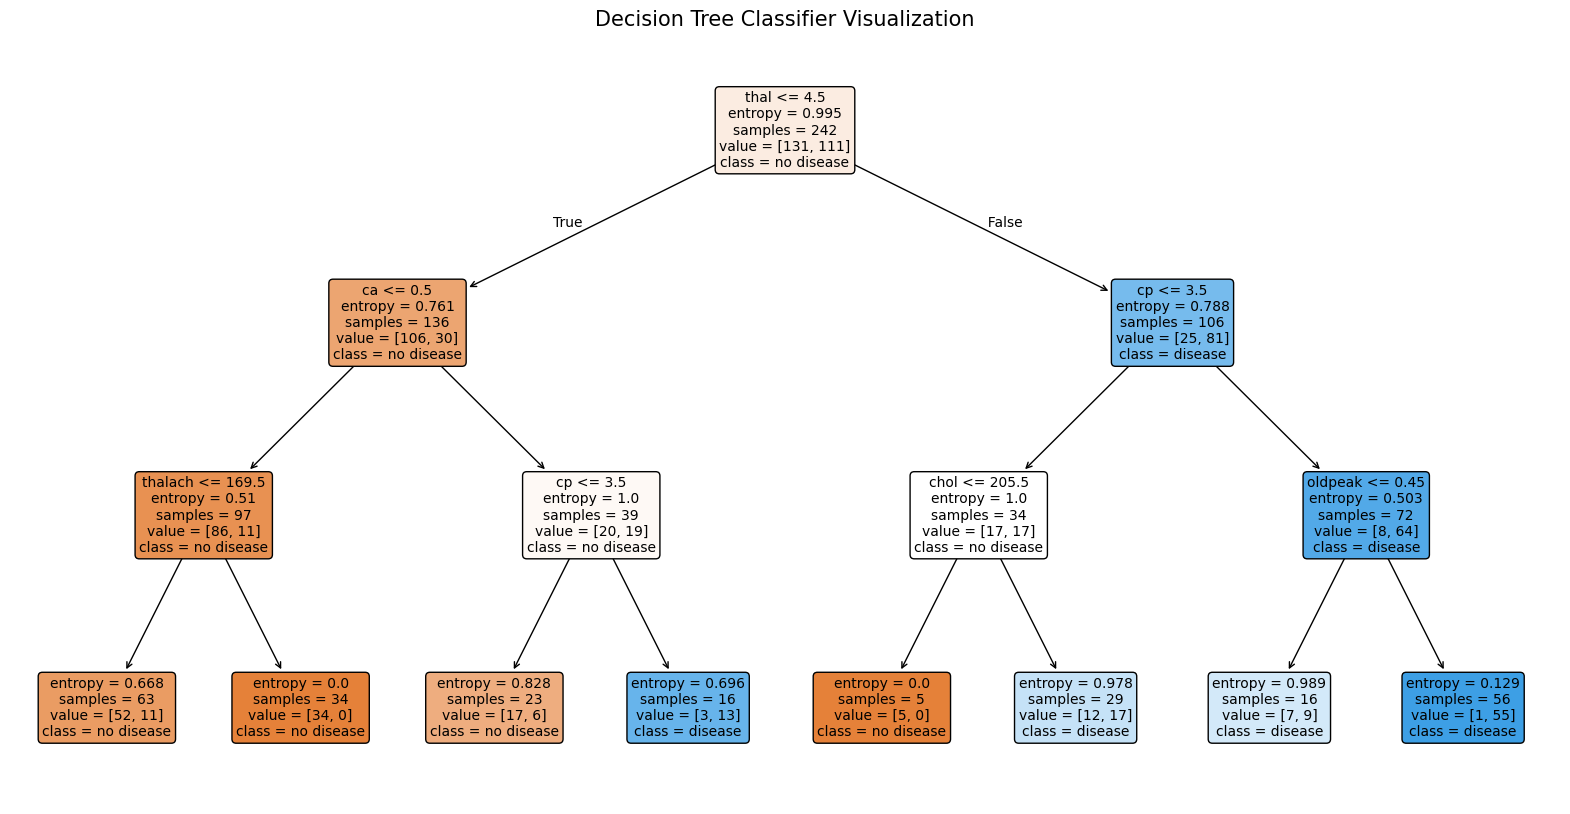

In [25]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Create a figure and an axes object for the plot
plt.figure(figsize=(20, 10))

# Plot the decision tree
plot_tree(
    dt_classifier,
    feature_names=X.columns.tolist(),
    class_names=['no disease', 'disease'],
    filled=True,
    rounded=True,
    fontsize=10
)

# Add a title to the plot
plt.title('Decision Tree Classifier Visualization', fontsize=15)

# Display the plot
plt.show()


## Hyperparameter Tuning (max_depth)

### Subtask:
Demonstrate how to experiment with different `max_depth` values for the Decision Tree. This step will involve retraining the model with varying depths and observing their impact on the evaluation metrics to illustrate hyperparameter tuning.


In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Define a range of max_depth values to experiment with
max_depth_values = range(1, 11)  # From 1 to 10

# Initialize a dictionary to store accuracy scores
accuracy_scores = {}

print("Experimenting with different max_depth values:\n")

for depth in max_depth_values:
    # Instantiate a Decision Tree Classifier with the current max_depth
    dt_classifier_tuned = DecisionTreeClassifier(
        criterion='entropy', random_state=42, max_depth=depth
    )

    # Train the model
    dt_classifier_tuned.fit(X_train, y_train)

    # Make predictions on the test set
    y_pred_tuned = dt_classifier_tuned.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred_tuned)

    # Store the accuracy score
    accuracy_scores[depth] = accuracy

    print(f"Max_depth: {depth}, Accuracy: {accuracy:.4f}")


Experimenting with different max_depth values:

Max_depth: 1, Accuracy: 0.7213
Max_depth: 2, Accuracy: 0.7705
Max_depth: 3, Accuracy: 0.8033
Max_depth: 4, Accuracy: 0.7869
Max_depth: 5, Accuracy: 0.7869
Max_depth: 6, Accuracy: 0.7213
Max_depth: 7, Accuracy: 0.7869
Max_depth: 8, Accuracy: 0.7213
Max_depth: 9, Accuracy: 0.8033
Max_depth: 10, Accuracy: 0.8033


---
## Step 10: Comparison Between KNN and Decision Tree

In [27]:
# حساب metrics من كود شريكك (dt_classifier, y_pred, conf_matrix)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

dt_acc  = accuracy_score(y_test, y_pred)
dt_prec = precision_score(y_test, y_pred, average='weighted')
dt_rec  = recall_score(y_test, y_pred, average='weighted')
dt_f1   = f1_score(y_test, y_pred, average='weighted')

# Comparison Table
comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    f'KNN (K={best_k})': [f'{knn_acc:.4f}', f'{knn_prec:.4f}', f'{knn_rec:.4f}', f'{knn_f1:.4f}'],
    'Decision Tree (depth=3)': [f'{dt_acc:.4f}', f'{dt_prec:.4f}', f'{dt_rec:.4f}', f'{dt_f1:.4f}']
}
comparison_df = pd.DataFrame(comparison_data)
print('=== Model Comparison ===')
print(comparison_df.to_string(index=False))

=== Model Comparison ===
   Metric KNN (K=9) Decision Tree (depth=3)
 Accuracy    0.9016                  0.8033
Precision    0.9190                  0.8056
   Recall    0.9016                  0.8033
 F1-Score    0.9015                  0.8036


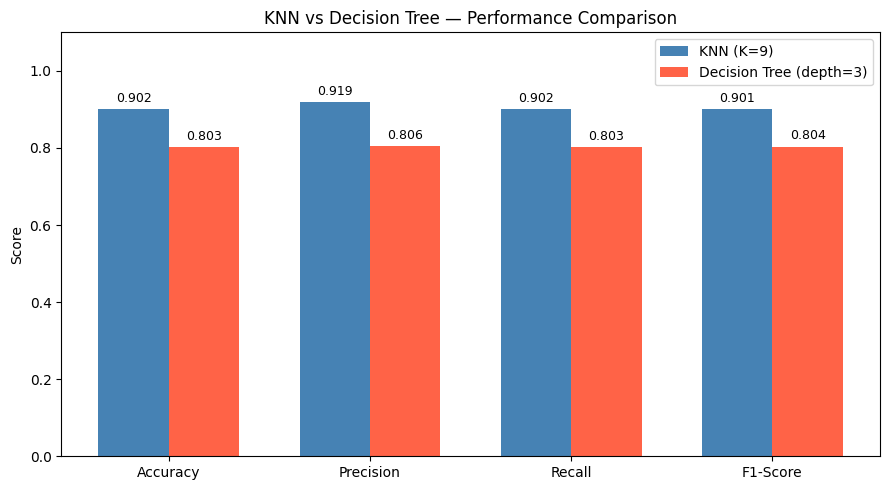

In [28]:
# Bar chart comparison
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
knn_scores = [knn_acc, knn_prec, knn_rec, knn_f1]
dt_scores  = [dt_acc,  dt_prec,  dt_rec,  dt_f1]

x = np.arange(len(metrics_names))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))
bars1 = ax.bar(x - width/2, knn_scores, width, label=f'KNN (K={best_k})', color='steelblue')
bars2 = ax.bar(x + width/2, dt_scores,  width, label='Decision Tree (depth=3)', color='tomato')

ax.set_ylabel('Score')
ax.set_title('KNN vs Decision Tree — Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.set_ylim(0, 1.1)
ax.legend()

for bar in bars1:
    ax.annotate(f'{bar.get_height():.3f}',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.annotate(f'{bar.get_height():.3f}',
                xy=(bar.get_x() + bar.get_width()/2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

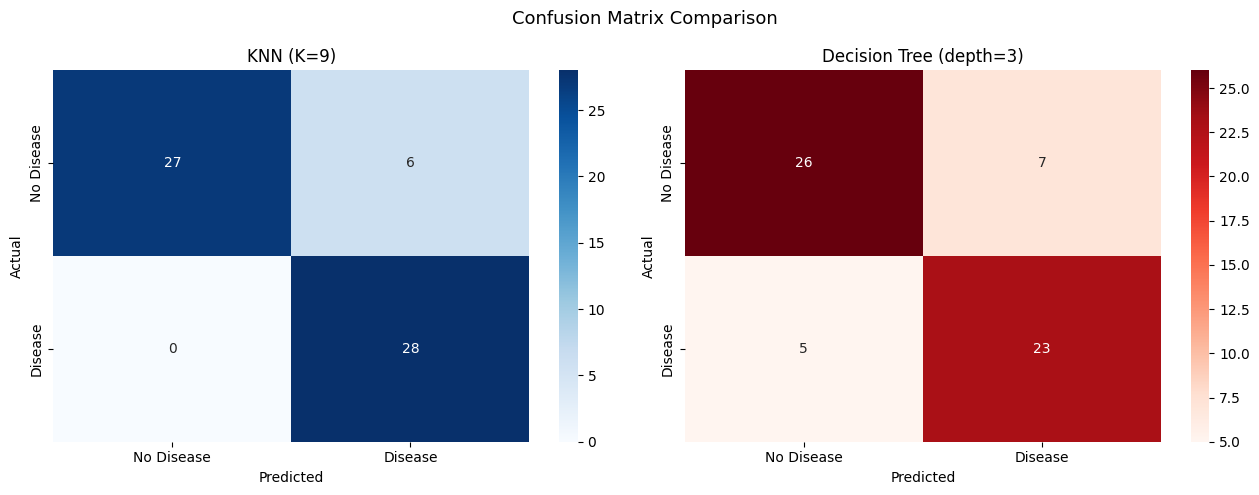

In [29]:
# Side-by-side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title(f'KNN (K={best_k})')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Reds',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Decision Tree (depth=3)')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.suptitle('Confusion Matrix Comparison', fontsize=13)
plt.tight_layout()
plt.show()

---
## Step 11: Discussion & Conclusion

### Analysis Summary

| Criterion | KNN | Decision Tree (ID3) |
|-----------|-----|--------------------|
| **Needs Scaling?** | ✅ Yes (distance-based) | ❌ No |
| **Interpretable?** | ❌ Black box | ✅ Visual tree |
| **Training Speed** | Fast (lazy learner) | Fast |
| **Prediction Speed** | Slow (searches all points) | Very Fast |
| **Sensitive to Noise?** | Yes (small K overfits) | Yes (deep trees overfit) |
| **Handles Imbalance?** | Moderate | Moderate |

### Conclusion
- **KNN** is simple and effective but requires normalization. Its performance depends heavily on the choice of K.
- **Decision Tree (ID3)** is interpretable and does not require feature scaling. It can overfit if depth is not controlled.
- For the Heart Disease dataset, the better model is determined by the metrics above.
- In medical applications, **Recall** is the most important metric (minimize false negatives).
